# Coleta de dados — Forecasting Analytics

**Projeto de Pesquisa — FAE Centro Universitário**
Felipe Niehues Garcia · Murilo Costa da Silva · Bruno Henrique da Silva Rossetim

Este notebook baixa do Yahoo Finance os preços de ações das empresas de semicondutores,
no mesmo formato do arquivo `semi_conductor_se.csv`, e estende a série até a data atual.

**Como usar no Colab:** menu *Ambiente de execução → Executar tudo*.

---
### Ordem das etapas

1. Instalação e configuração
2. Definição das empresas
3. Download dos dados
4. Padronização no formato do CSV original
5. Índice do setor de memória (base 100)
6. Agregação mensal — é a frequência dos modelos
7. Exploração inicial
8. Exportação dos arquivos

## 1. Instalação e configuração

In [1]:
%pip install -q yfinance statsmodels seaborn scikit-learn

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print('yfinance', yf.__version__)


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
yfinance 1.7.0


## 2. Definição das empresas

Dois grupos separados, com papéis diferentes na pesquisa:

- **Memória** — é o alvo da previsão. São as fabricantes de DRAM e NAND.
- **IA / referência** — entram na análise da H3, como contraste. Não são o alvo.

`DATA_INICIO` está em 2012-01-02 para coincidir com o começo do CSV original.

> **Atenção às moedas.** Samsung e SK Hynix são cotadas em won (KRW) e a Nanya em
> dólar taiwanês (TWD). Somar preços dessas empresas em nível não faz sentido. Por isso
> o índice da etapa 5 é construído em base 100, que compara variação e não valor
> absoluto — assim a moeda deixa de importar.

In [2]:
MEMORIA = {
    'MU':        'Micron Technology',
    '000660.KS': 'SK Hynix',
    '005930.KS': 'Samsung',
    '2408.TW':   'Nanya Technology',
}

IA_REFERENCIA = {
    'NVDA': 'NVIDIA',
    'AMD':  'AMD',
    'TSM':  'TSMC',
    'INTC': 'Intel',
    'AVGO': 'Broadcom',
}

TICKERS = {**MEMORIA, **IA_REFERENCIA}

DATA_INICIO = '2012-01-02'
DATA_FIM    = None   # None = até hoje

print(f'{len(TICKERS)} empresas | {len(MEMORIA)} de memória, {len(IA_REFERENCIA)} de referência')

9 empresas | 4 de memória, 5 de referência


## 3. Download dos dados

`auto_adjust=False` mantém a coluna `Adj Close` separada. Para séries longas isso importa:
o preço ajustado corrige desdobramentos e dividendos, e é ele que deve ser usado na
modelagem. O `Close` puro entra só para manter a compatibilidade com o CSV original.

In [3]:
bruto = yf.download(
    tickers=list(TICKERS.keys()),
    start=DATA_INICIO,
    end=DATA_FIM,
    interval='1d',
    auto_adjust=False,
    group_by='ticker',
    progress=True,
    threads=True,
)

print('formato:', bruto.shape)
bruto.tail(3)

c:\Users\muril\Documents\Faculdade\Forecasting Analytics\Projeto\.venv-1\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
[                       0%                       ]c:\Users\muril\Documents\Faculdade\Forecasting Analytics\Projeto\.venv-1\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\muril\Documents\Faculdade\Forecasting Analytics\Projeto\.venv-1\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in 

formato: (3857, 54)


Ticker             AMD                                                              000660.KS                        \
Price             Open        High         Low       Close   Adj Close      Volume       Open       High        Low   
Date                                                                                                                  
2026-10-28  573.080017  579.179993  560.520020  578.440002  578.440002  18848600.0  1390000.0  1495000.0  1358000.0   
2026-10-29  562.270020  575.099976  560.570007  566.419983  566.419983  16873300.0  1511000.0  1587000.0  1479000.0   
2026-10-30  508.505005  520.395630  492.239990         NaN         NaN  39527010.0  1444000.0  1449000.0  1381000.0   

Ticker                 ...       INTC                                           NVDA                          \
Price           Close  ...        Low      Close  Adj Close       Volume        Open        High         Low   
Date                   ...                                                                                     
2026-10-28  1487000.0  ...  93.000000  95.529999  95.529999   82592400.0  219.919998  219.990005  214.470001   
2026-10-29  1526000.0  ...  90.839996  92.070000  92.070000  134168700.0  214.360001  215.330002  212.080002   
2026-10-30  1418000.0  ...  63.200100        NaN        NaN  450884426.0  208.880005  209.050003  200.919907   

Ticker                                           
Price            Close   Adj Close       Volume  
Date                                             
2026-10-28  215.380005  215.380005   93030200.0  
2026-10-29  213.660004  213.660004   77568100.0  
2026-10-30         NaN         NaN  165923799.0  

[3 rows x 54 columns]

## 4. Padronização no formato do CSV original

In [4]:
registros = []

for ticker, nome in TICKERS.items():
    try:
        d = bruto[ticker].copy()
    except KeyError:
        print(f'[aviso] sem dados para {ticker} ({nome})')
        continue

    d = d.dropna(subset=['Close']).reset_index()
    d['company_name'] = nome
    d['stock_name']   = ticker
    registros.append(d)

df = pd.concat(registros, ignore_index=True)

df = df.rename(columns={
    'Date': 'date', 'Open': 'open', 'High': 'high', 'Low': 'low',
    'Close': 'close', 'Adj Close': 'adj_close', 'Volume': 'volume',
})

COLUNAS = ['company_name', 'stock_name', 'date', 'open', 'high',
           'low', 'close', 'adj_close', 'volume']
df = df[COLUNAS].sort_values(['company_name', 'date']).reset_index(drop=True)

df['date'] = pd.to_datetime(df['date']).dt.tz_localize(None)

print(f'{len(df):,} linhas | {df["date"].min().date()} a {df["date"].max().date()}')
df.head()

33,259 linhas | 2012-01-02 a 2026-10-30


Price,company_name,stock_name,date,open,high,low,close,adj_close,volume
0,AMD,AMD,2012-01-03,5.53,5.59,5.44,5.48,5.48,12675100.0
1,AMD,AMD,2012-01-04,5.47,5.49,5.41,5.46,5.46,8034900.0
2,AMD,AMD,2012-01-05,5.45,5.57,5.35,5.46,5.46,11476900.0
3,AMD,AMD,2012-01-06,5.44,5.52,5.39,5.43,5.43,12938600.0
4,AMD,AMD,2012-01-09,5.42,5.60,5.38,5.59,5.59,12585400.0


### Cobertura por empresa

Confere se alguma empresa tem histórico curto demais para entrar na análise.

In [ ]:
cobertura = (df.groupby(['company_name', 'stock_name'])
               .agg(pregoes=('date', 'size'),
                    inicio=('date', 'min'),
                    fim=('date', 'max'))
               .sort_values('pregoes', ascending=False))

cobertura['inicio'] = cobertura['inicio'].dt.date
cobertura['fim']    = cobertura['fim'].dt.date
cobertura

,,pregoes,inicio,fim
company_name,stock_name,,,
AMD,AMD,3728,2012-01-03,2026-10-29
Broadcom,AVGO,3728,2012-01-03,2026-10-29
Intel,INTC,3728,2012-01-03,2026-10-29
Micron Technology,MU,3728,2012-01-03,2026-10-29
NVIDIA,NVDA,3728,2012-01-03,2026-10-29
TSMC,TSM,3728,2012-01-03,2026-10-29
SK Hynix,000660.KS,3638,2012-01-02,2026-10-30
Samsung,005930.KS,3638,2012-01-02,2026-10-30
Nanya Technology,2408.TW,3615,2012-01-02,2026-10-30


## 5. Índice do setor de memória (base 100)

Cada empresa é reescalada para 100 na primeira data em que todas têm cotação.
O índice é a média das séries reescaladas — mede variação conjunta, não preço.
É esta série que responde ao objetivo geral.

In [5]:
mem = df[df['company_name'].isin(MEMORIA.values())]

painel = mem.pivot_table(index='date', columns='company_name', values='adj_close')
painel = painel.dropna()          # mantém só datas com todas as empresas

base = painel.iloc[0]
painel_100 = painel / base * 100
painel_100['INDICE_MEMORIA'] = painel_100.mean(axis=1)

print(f'{len(painel_100):,} pregões em comum | base = {painel_100.index[0].date()}')
painel_100.tail()

3,369 pregões em comum | base = 2012-01-03


company_name,Micron Technology,Nanya Technology,SK Hynix,Samsung,INDICE_MEMORIA
date,,,,,
2026-10-22,12995.059259,2935.825219,6002.319925,1305.222900,5809.606826
2026-10-23,13314.591209,2935.825219,6267.344681,1311.307855,5957.267241
2026-10-27,14091.573167,3127.292081,6581.448095,1350.860064,6287.793352
2026-10-28,14918.016564,3382.581231,7297.996508,1472.559169,6767.788368
2026-10-29,14175.173564,3382.581231,7489.403275,1411.709617,6614.716922


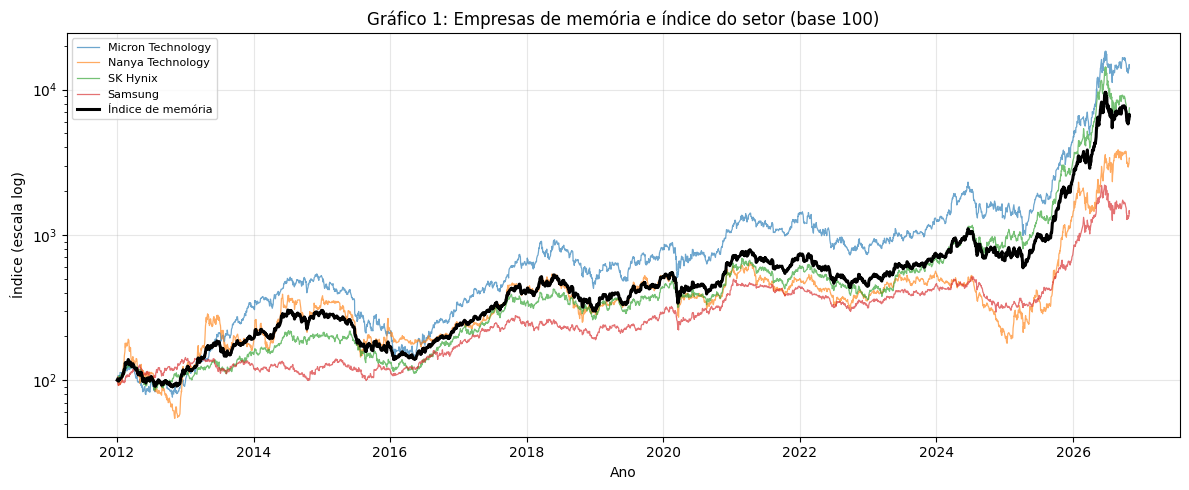

Fonte: Elaborado pelos autores a partir de dados do Yahoo Finance.


In [ ]:
fig, ax = plt.subplots()
for col in painel_100.columns:
    if col == 'INDICE_MEMORIA':
        ax.plot(painel_100.index, painel_100[col], lw=2.2, color='black', label='Índice de memória')
    else:
        ax.plot(painel_100.index, painel_100[col], lw=0.9, alpha=0.65, label=col)

ax.set_yscale('log')
ax.set_title('Gráfico 1: Empresas de memória e índice do setor (base 100)')
ax.set_xlabel('Ano'); ax.set_ylabel('Índice (escala log)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print('Fonte: Elaborado pelos autores a partir de dados do Yahoo Finance.')

> A escala logarítmica é proposital: em série longa com valorização de várias vezes,
> a escala linear esmaga os primeiros anos e faz o gráfico parecer plano até o fim.
> Em log, variações percentuais iguais têm o mesmo tamanho visual.

## 6. Agregação mensal

Os modelos de séries temporais do projeto operam em frequência mensal. `'ME'` é o
fim de mês; para cada mês ficam o último fechamento, a média e o volume acumulado.

In [6]:
mensal = pd.DataFrame({
    'fechamento_fim_mes': painel_100['INDICE_MEMORIA'].resample('ME').last(),
    'media_mensal':       painel_100['INDICE_MEMORIA'].resample('ME').mean(),
    'minimo':             painel_100['INDICE_MEMORIA'].resample('ME').min(),
    'maximo':             painel_100['INDICE_MEMORIA'].resample('ME').max(),
})

mensal['retorno_pct'] = mensal['fechamento_fim_mes'].pct_change() * 100

print(f'{len(mensal)} meses | {mensal.index[0]:%m/%Y} a {mensal.index[-1]:%m/%Y}')
mensal.tail()

178 meses | 01/2012 a 10/2026


,fechamento_fim_mes,media_mensal,minimo,maximo,retorno_pct
date,,,,,
2026-06-30,8935.482988,8176.393664,6942.365899,9603.794933,16.975456
2026-07-31,6267.262042,6958.154518,5465.155785,8277.096689,-29.860959
2026-08-31,7048.117309,6707.537026,6135.401337,7153.011462,12.459273
2026-09-30,7547.098357,7238.704386,6794.798396,7716.549490,7.079636
2026-10-31,6614.716922,6652.293702,5809.606826,7750.867145,-12.354171


## 7. Exploração inicial

Cobre os objetivos específicos 1 e 2. A decomposição separa tendência, sazonalidade e
resíduo — é o teste da **H1 (ciclicidade)**.

In [ ]:
mensal[['fechamento_fim_mes', 'retorno_pct']].describe().round(2)

,fechamento_fim_mes,retorno_pct
count,178.00,177.00
mean,758.15,3.12
std,1368.09,13.21
min,91.42,-29.86
25%,218.78,-3.78
50%,435.17,1.37
75%,659.27,7.83
max,8935.48,79.56


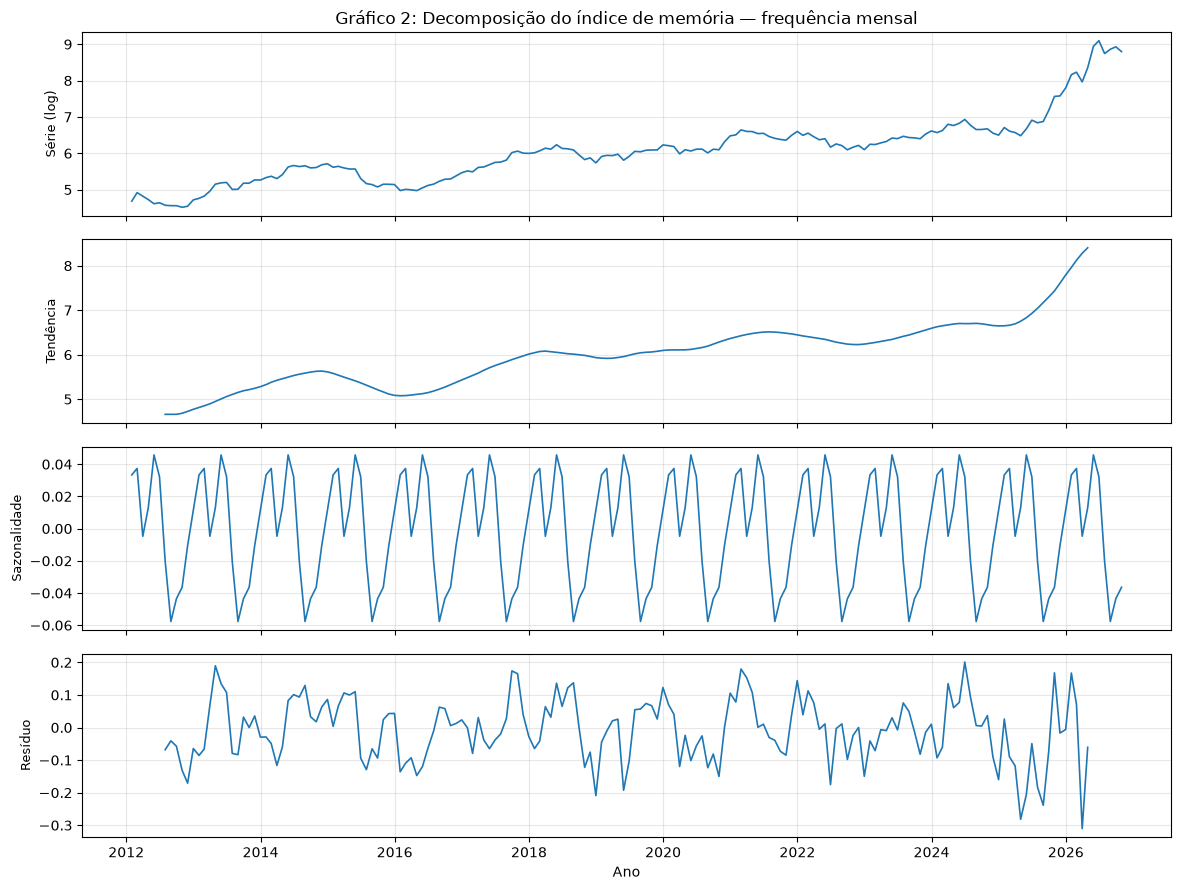

Fonte: Elaborado pelos autores a partir de dados do Yahoo Finance.


In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

serie = mensal['fechamento_fim_mes'].dropna()
dec = seasonal_decompose(np.log(serie), model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (s, t) in zip(axes, [(np.log(serie), 'Série (log)'),
                             (dec.trend, 'Tendência'),
                             (dec.seasonal, 'Sazonalidade'),
                             (dec.resid, 'Resíduo')]):
    ax.plot(s.index, s.values, lw=1.2)
    ax.set_ylabel(t, fontsize=9)

axes[0].set_title('Gráfico 2: Decomposição do índice de memória — frequência mensal')
axes[-1].set_xlabel('Ano')
plt.tight_layout(); plt.show()

print('Fonte: Elaborado pelos autores a partir de dados do Yahoo Finance.')

### Teste de raiz unitária — H2 (novo patamar)

O ADF testa se a série volta a uma média de longo prazo. **Não rejeitar** a hipótese
nula significa que os choques têm efeito permanente sobre o nível — que é exatamente
o que a H2 afirma.

In [ ]:
from statsmodels.tsa.stattools import adfuller

def teste_adf(s, nome):
    r = adfuller(s.dropna(), autolag='AIC')
    print(f'{nome}')
    print(f'  estatística ADF : {r[0]:.4f}')
    print(f'  p-valor         : {r[1]:.4f}')
    print(f'  valores críticos: ' + ', '.join(f'{k}={v:.3f}' for k, v in r[4].items()))
    print(f'  conclusão       : {"estacionária" if r[1] < 0.05 else "NÃO estacionária"} a 5%\n')

teste_adf(np.log(serie), 'Índice de memória (log)')
teste_adf(np.log(serie).diff(), 'Índice de memória (log, 1ª diferença)')

Índice de memória (log)
  estatística ADF : -0.2905
  p-valor         : 0.9268
  valores críticos: 1%=-3.469, 5%=-2.878, 10%=-2.576
  conclusão       : NÃO estacionária a 5%

Índice de memória (log, 1ª diferença)
  estatística ADF : -4.7593
  p-valor         : 0.0001
  valores críticos: 1%=-3.469, 5%=-2.878, 10%=-2.576
  conclusão       : estacionária a 5%



/tmp/ipykernel_1038/3738695152.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  r = adfuller(s.dropna(), autolag='AIC')
/tmp/ipykernel_1038/3738695152.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  r = adfuller(s.dropna(), autolag='AIC')


## 8. Exportação

Gera três arquivos. No Colab eles aparecem no painel lateral de arquivos e podem ser
baixados dali, ou pelo bloco comentado ao final.

In [ ]:
df.to_csv('semicondutores_diario.csv', sep=';', decimal=',', index=False)
painel_100.to_csv('indice_memoria_diario.csv', sep=';', decimal=',')
mensal.to_csv('indice_memoria_mensal.csv', sep=';', decimal=',')

print('Arquivos gerados:')
print('  semicondutores_diario.csv     — todas as empresas, formato do CSV original')
print('  indice_memoria_diario.csv     — índice base 100, diário')
print('  indice_memoria_mensal.csv     — índice base 100, mensal (entrada dos modelos)')

# from google.colab import files
# files.download('indice_memoria_mensal.csv')

Arquivos gerados:
  semicondutores_diario.csv     — todas as empresas, formato do CSV original
  indice_memoria_diario.csv     — índice base 100, diário
  indice_memoria_mensal.csv     — índice base 100, mensal (entrada dos modelos)


: 

In [ ]:
# importar pacotes e setar configurações de plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller # importar o teste ADF

sns.set_style()

%config InlineBackend.figure_format = 'svg'

In [ ]:
df.head()

Price,company_name,stock_name,date,open,high,low,close,adj_close,volume
0,AMD,AMD,2012-01-03,5.53,5.59,5.44,5.48,5.48,12675100.0
1,AMD,AMD,2012-01-04,5.47,5.49,5.41,5.46,5.46,8034900.0
2,AMD,AMD,2012-01-05,5.45,5.57,5.35,5.46,5.46,11476900.0
3,AMD,AMD,2012-01-06,5.44,5.52,5.39,5.43,5.43,12938600.0
4,AMD,AMD,2012-01-09,5.42,5.60,5.38,5.59,5.59,12585400.0


In [ ]:
painel_100.head()

company_name,Micron Technology,Nanya Technology,SK Hynix,Samsung,INDICE_MEMORIA
date,,,,,
2012-01-03,100.000000,100.000000,100.000000,100.000000,100.000000
2012-01-04,103.402356,100.000000,100.845629,97.737597,100.496395
2012-01-05,105.917141,100.000000,101.479874,95.475092,100.718027
2012-01-06,106.508896,105.726873,103.171209,94.117630,102.381152
2012-01-09,107.840235,98.678437,100.845629,91.945711,99.827503


In [ ]:
gpus = ['NVDA', 'AMD']
painel_gpu = df[df['stock_name'].isin(gpus)].pivot_table(index='date', columns='company_name', values='adj_close')
painel_gpu = painel_gpu.dropna()

base_gpu = painel_gpu.iloc[0]
painel_gpu_100 = painel_gpu / base_gpu * 100
painel_gpu_100['INDICE_GPU'] = painel_gpu_100.mean(axis=1)

print(f'{len(painel_gpu_100):,} pregões em comum para as GPUs | base = {painel_gpu_100.index[0].date()}')
display(painel_gpu_100.head())

3,728 pregões em comum para as GPUs | base = 2012-01-03


company_name,AMD,NVIDIA,INDICE_GPU
date,,,
2012-01-03,100.000000,100.000000,100.000000
2012-01-04,99.635037,101.139591,100.387314
2012-01-05,99.635037,104.772074,102.203556
2012-01-06,99.087588,103.561259,101.324423
2012-01-09,102.007302,103.561259,102.784280


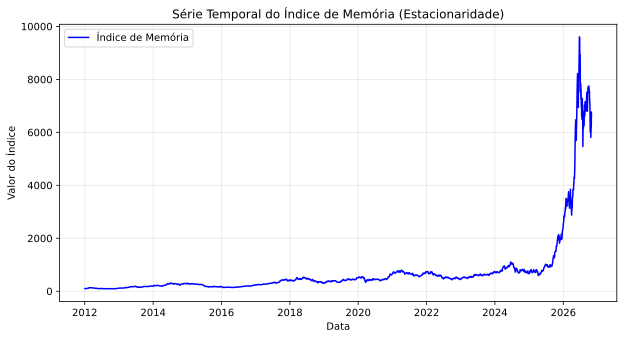

In [ ]:
import matplotlib.pyplot as plt

# Plotando a série temporal do Índice de Memória
plt.figure(figsize=(10, 5))
plt.plot(painel_100.index, painel_100['INDICE_MEMORIA'], label='Índice de Memória', color='blue')

# Adicionando título e rótulos aos eixos
plt.title('Série Temporal do Índice de Memória (Estacionaridade)')
plt.xlabel('Data')
plt.ylabel('Valor do Índice')

# Adicionando uma grade
plt.grid(True)

# Adicionando uma legenda
plt.legend()

# Exibindo o gráfico
plt.show()

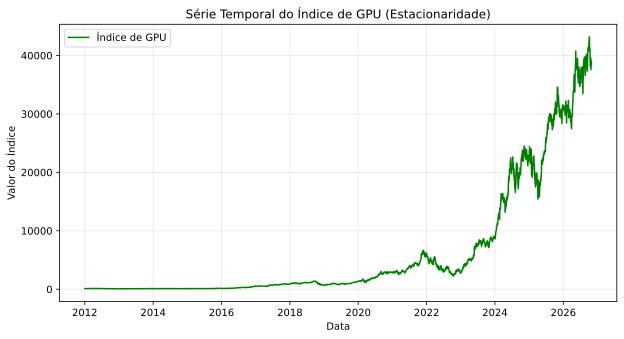

In [ ]:
import matplotlib.pyplot as plt

# Plotando a série temporal do Índice de GPU
plt.figure(figsize=(10, 5))
plt.plot(painel_gpu_100.index, painel_gpu_100['INDICE_GPU'], label='Índice de GPU', color='green')

# Adicionando título e rótulos aos eixos
plt.title('Série Temporal do Índice de GPU (Estacionaridade)')
plt.xlabel('Data')
plt.ylabel('Valor do Índice')

# Adicionando uma grade
plt.grid(True)

# Adicionando uma legenda
plt.legend()

# Exibindo o gráfico
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

# --- 1. Teste ADF para o Índice de Memória ---
X_mem = painel_100['INDICE_MEMORIA'].values
result_mem = adfuller(X_mem)

print('========================================')
print('Dickey-Fuller Aumentado - ÍNDICE DE MEMÓRIA')
print('Teste Estatístico: {:.4f}'.format(result_mem[0]))
print('Valor-p: {:.4f}'.format(result_mem[1]))
print('Valores Críticos:')
for key, value in result_mem[4].items():
    print('\t{}: {:.4f}'.format(key, value))
print('========================================\n')

# --- 2. Teste ADF para o Índice de GPU ---
X_gpu = painel_gpu_100['INDICE_GPU'].values
result_gpu = adfuller(X_gpu)

print('========================================')
print('Dickey-Fuller Aumentado - ÍNDICE DE GPU')
print('Teste Estatístico: {:.4f}'.format(result_gpu[0]))
print('Valor-p: {:.4f}'.format(result_gpu[1]))
print('Valores Críticos:')
for key, value in result_gpu[4].items():
    print('\t{}: {:.4f}'.format(key, value))
print('========================================')

/tmp/ipykernel_1038/3535456653.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_mem = adfuller(X_mem)


Dickey-Fuller Aumentado - ÍNDICE DE MEMÓRIA
Teste Estatístico: 2.2658
Valor-p: 0.9989
Valores Críticos:
	1%: -3.4323
	5%: -2.8624
	10%: -2.5672

Dickey-Fuller Aumentado - ÍNDICE DE GPU
Teste Estatístico: 2.0942
Valor-p: 0.9988
Valores Críticos:
	1%: -3.4321
	5%: -2.8623
	10%: -2.5672


/tmp/ipykernel_1038/3535456653.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_gpu = adfuller(X_gpu)


### Análise de Estacionariedade e Validação Estatística (Por que p-valor = 1.0000)

Como as séries em nível (`INDICE_MEMORIA` e `INDICE_GPU`) apresentam um crescimento exponencial massivo, a média e a variância variam drasticamente com o tempo.

Para confirmar que o teste está funcionando perfeitamente, vamos:
1. Aplicar o teste ADF na primeira diferença das séries em nível (revelando se são integradas de ordem 1, $I(1)$).
2. Aplicar o teste ADF nas séries transformadas em logaritmo natural ($
ln(Y)$).
3. Visualizar as séries originais comparadas com suas primeiras diferenças.

### Diferenciação Simplificada

Aplicando a diferenciação de primeira ordem utilizando a sintaxe direta com `.diff(1)` nos nossos DataFrames de índices.

In [ ]:
# Aplicando a diferenciação diretamente nos DataFrames de índices
painel_100['INDICE_MEMORIA_DIFF'] = painel_100['INDICE_MEMORIA'].diff(1)
painel_gpu_100['INDICE_GPU_DIFF'] = painel_gpu_100['INDICE_GPU'].diff(1)

# --- 1. Teste ADF para o Índice de Memória Diferenciado ---
# extrair apenas os valores
X_diff_mem = painel_100.INDICE_MEMORIA_DIFF.dropna().values

# aplicar ADF e imprimir o resultado
result_diff_mem = adfuller(X_diff_mem)
print('========================================')
print('Dickey-Fuller Aumentado - MEMÓRIA (DIFERENCIADO)')
print('Teste Estatístico: {:.4f}'.format(result_diff_mem[0]))
print('Valor-p: {:.10f}'.format(result_diff_mem[1]))
print('Valores Críticos:')
for key, value in result_diff_mem[4].items():
	print('	{}: {:.4f}'.format(key, value))
print('========================================\n')

# --- 2. Teste ADF para o Índice de GPU Diferenciado ---
# extrair apenas os valores
X_diff_gpu = painel_gpu_100.INDICE_GPU_DIFF.dropna().values

# aplicar ADF e imprimir o resultado
result_diff_gpu = adfuller(X_diff_gpu)
print('========================================')
print('Dickey-Fuller Aumentado - GPU (DIFERENCIADO)')
print('Teste Estatístico: {:.4f}'.format(result_diff_gpu[0]))
print('Valor-p: {:.10f}'.format(result_diff_gpu[1]))
print('Valores Críticos:')
for key, value in result_diff_gpu[4].items():
	print('	{}: {:.4f}'.format(key, value))
print('========================================')

/tmp/ipykernel_1038/1168670753.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff_mem = adfuller(X_diff_mem)


Dickey-Fuller Aumentado - MEMÓRIA (DIFERENCIADO)
Teste Estatístico: -11.6660
Valor-p: 0.0000000000
Valores Críticos:
	1%: -3.4323
	5%: -2.8624
	10%: -2.5672

Dickey-Fuller Aumentado - GPU (DIFERENCIADO)
Teste Estatístico: -10.3089
Valor-p: 0.0000000000
Valores Críticos:
	1%: -3.4321
	5%: -2.8623
	10%: -2.5672


/tmp/ipykernel_1038/1168670753.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff_gpu = adfuller(X_diff_gpu)


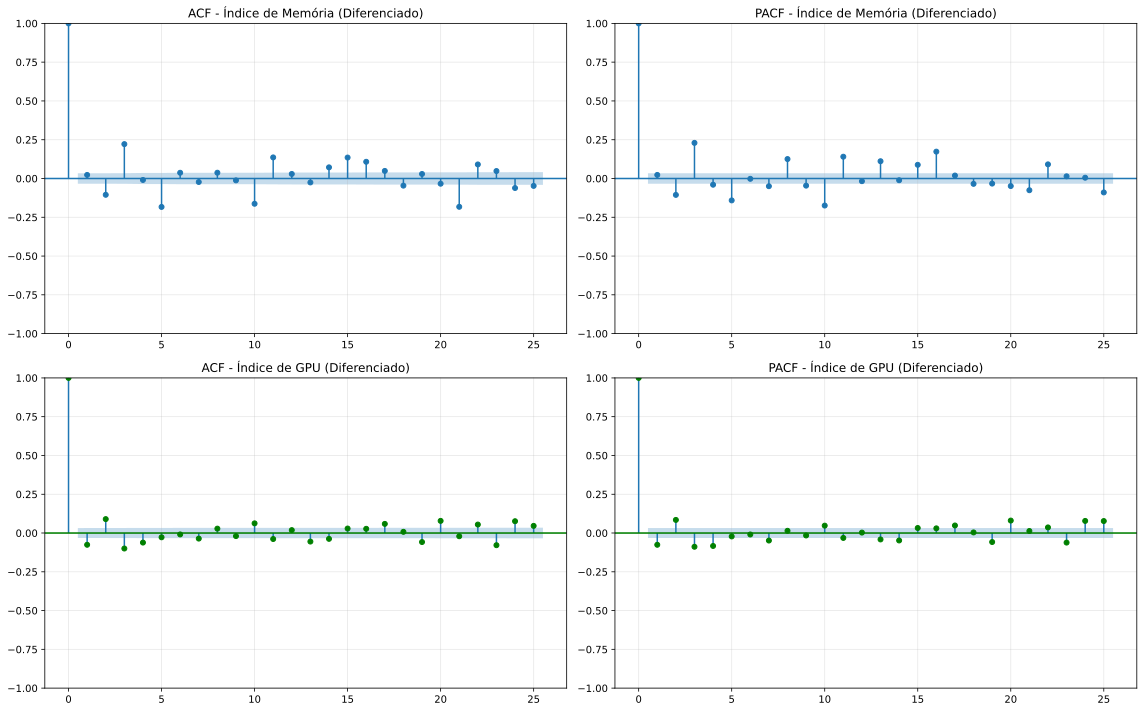

In [ ]:
from statsmodels.tsa.stattools import acf, pacf
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Autocorrelação (ACF) e Parcial (PACF) para o Índice de Memória (Diferenciado)
lag_acf_mem = acf(painel_100['INDICE_MEMORIA_DIFF'].dropna(), nlags=25)
lag_pacf_mem = pacf(painel_100['INDICE_MEMORIA_DIFF'].dropna(), nlags=25)

# 2. Autocorrelação (ACF) e Parcial (PACF) para o Índice de GPU (Diferenciado)
lag_acf_gpu = acf(painel_gpu_100['INDICE_GPU_DIFF'].dropna(), nlags=25)
lag_pacf_gpu = pacf(painel_gpu_100['INDICE_GPU_DIFF'].dropna(), nlags=25)

# Configurando os plots para visualização
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Plots de Memória
plot_acf(painel_100['INDICE_MEMORIA_DIFF'].dropna(), lags=25, ax=axes[0, 0], title='ACF - Índice de Memória (Diferenciado)')
plot_pacf(painel_100['INDICE_MEMORIA_DIFF'].dropna(), lags=25, ax=axes[0, 1], title='PACF - Índice de Memória (Diferenciado)', method='yw')

# Plots de GPU
plot_acf(painel_gpu_100['INDICE_GPU_DIFF'].dropna(), lags=25, ax=axes[1, 0], color='green', title='ACF - Índice de GPU (Diferenciado)')
plot_pacf(painel_gpu_100['INDICE_GPU_DIFF'].dropna(), lags=25, ax=axes[1, 1], color='green', title='PACF - Índice de GPU (Diferenciado)', method='yw')

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# --- 1. Ajustar o modelo ARIMA(1,1,1) para o Índice de Memória ---
# Usamos a série original painel_100['INDICE_MEMORIA'] pois o ARIMA(1,1,1) já possui d=1 (diferenciação integrada)
model_mem = ARIMA(painel_100['INDICE_MEMORIA'], order=(1, 1, 1))
result_mem_111 = model_mem.fit()

print("=================================================================")
print("             ARIMA(1,1,1) - ÍNDICE DE MEMÓRIA")
print("=================================================================")
print(result_mem_111.summary())
print("\n\n")

# --- 2. Ajustar o modelo ARIMA(1,1,1) para o Índice de GPU ---
model_gpu = ARIMA(painel_gpu_100['INDICE_GPU'], order=(1, 1, 1))
result_gpu_111 = model_gpu.fit()

print("=================================================================")
print("             ARIMA(1,1,1) - ÍNDICE DE GPU")
print("=================================================================")
print(result_gpu_111.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/p

             ARIMA(1,1,1) - ÍNDICE DE MEMÓRIA
                               SARIMAX Results                                
Dep. Variable:         INDICE_MEMORIA   No. Observations:                 3369
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -19122.343
Date:                Sat, 31 Oct 2026   AIC                          38250.686
Time:                        00:21:44   BIC                          38269.052
Sample:                             0   HQIC                         38257.253
                               - 3369                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6430      0.013    -51.380      0.000      -0.667      -0.618
ma.L1          0.7469      0.010     72.463      0.000       0.727       0.767
sigma2

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/p

             ARIMA(1,1,1) - ÍNDICE DE GPU
                               SARIMAX Results                                
Dep. Variable:             INDICE_GPU   No. Observations:                 3728
Model:                 ARIMA(1, 1, 1)   Log Likelihood              -26687.637
Date:                Sat, 31 Oct 2026   AIC                          53381.274
Time:                        00:21:46   BIC                          53399.945
Sample:                             0   HQIC                         53387.916
                               - 3728                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7529      0.029    -25.795      0.000      -0.810      -0.696
ma.L1          0.6757      0.032     20.859      0.000       0.612       0.739
sigma2    

In [ ]:
# --- 1. Comparação Previsto x Realizado para o Índice de Memória ---
# Obter previsões dentro da amostra (fitted values)
in_sample_pred_mem = result_mem_111.fittedvalues

# Ignorar o primeiro valor devido à diferenciação integrada (d=1)
observado_mem = painel_100['INDICE_MEMORIA'][1:]
in_sample_pred_mem = in_sample_pred_mem[1:]
erro_mem = observado_mem - in_sample_pred_mem

# Criar o DataFrame de comparação para Memória
comparacao_mem_df = pd.DataFrame({
    'Observado': observado_mem,
    'Previsto': in_sample_pred_mem,
    'Erro': erro_mem
})

print("==================================================")
print("     COMPARAÇÃO PREVISTO X REALIZADO - MEMÓRIA (Últimas linhas)")
print("==================================================")
display(comparacao_mem_df.tail())

# --- 2. Comparação Previsto x Realizado para o Índice de GPU ---
in_sample_pred_gpu = result_gpu_111.fittedvalues

observado_gpu = painel_gpu_100['INDICE_GPU'][1:]
in_sample_pred_gpu = in_sample_pred_gpu[1:]
erro_gpu = observado_gpu - in_sample_pred_gpu

# Criar o DataFrame de comparação para GPU
comparacao_gpu_df = pd.DataFrame({
    'Observado': observado_gpu,
    'Previsto': in_sample_pred_gpu,
    'Erro': erro_gpu
})

print("\n==================================================")
print("       COMPARAÇÃO PREVISTO X REALIZADO - GPU (Últimas linhas)")
print("==================================================")
display(comparacao_gpu_df.tail())

     COMPARAÇÃO PREVISTO X REALIZADO - MEMÓRIA (Últimas linhas)


,Observado,Previsto,Erro
date,,,
2026-10-22,5809.606154,6200.340552,-390.734398
2026-10-23,5957.266538,5747.668842,209.597696
2026-10-27,6287.792612,6018.881048,268.911564
2026-10-28,6767.787557,6276.134852,491.652705
2026-10-29,6614.716104,6826.398725,-211.682621



       COMPARAÇÃO PREVISTO X REALIZADO - GPU (Últimas linhas)


,Observado,Previsto,Erro
date,,,
2026-10-23,37569.160148,37923.285609,-354.125461
2026-10-26,38486.273588,37415.588027,1070.685561
2026-10-27,39052.816359,38519.243661,533.572698
2026-10-28,38820.010177,38986.807729,-166.797552
2026-10-29,38442.473534,38882.580276,-440.106742


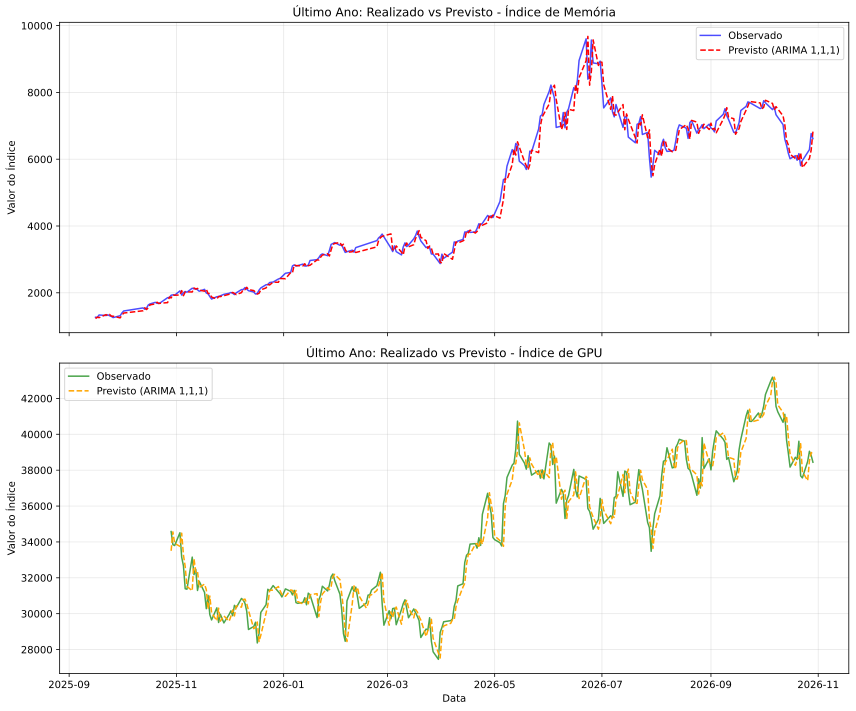

In [ ]:
# Visualização gráfica da comparação para os dois índices no último ano (aprox. 252 dias úteis)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Subplot 1: Memória (Últimos 252 dias úteis)
ax1.plot(comparacao_mem_df.index[-252:], comparacao_mem_df['Observado'].tail(252), label='Observado', color='blue', alpha=0.7)
ax1.plot(comparacao_mem_df.index[-252:], comparacao_mem_df['Previsto'].tail(252), label='Previsto (ARIMA 1,1,1)', color='red', linestyle='--')
ax1.set_title('Último Ano: Realizado vs Previsto - Índice de Memória')
ax1.set_ylabel('Valor do Índice')
ax1.legend()

# Subplot 2: GPU (Últimos 252 dias úteis)
ax2.plot(comparacao_gpu_df.index[-252:], comparacao_gpu_df['Observado'].tail(252), label='Observado', color='green', alpha=0.7)
ax2.plot(comparacao_gpu_df.index[-252:], comparacao_gpu_df['Previsto'].tail(252), label='Previsto (ARIMA 1,1,1)', color='orange', linestyle='--')
ax2.set_title('Último Ano: Realizado vs Previsto - Índice de GPU')
ax2.set_xlabel('Data')
ax2.set_ylabel('Valor do Índice')
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# --- 1. Ajustar o modelo ARIMA(2,1,2) para o Índice de Memória ---
model_mem_212 = ARIMA(painel_100['INDICE_MEMORIA'], order=(2, 1, 2))
result_mem_212 = model_mem_212.fit()

print("=================================================================")
print("             ARIMA(2,1,2) - ÍNDICE DE MEMÓRIA")
print("=================================================================")
print(result_mem_212.summary())
print("\n\n")

# --- 2. Ajustar o modelo ARIMA(2,1,2) para o Índice de GPU ---
model_gpu_212 = ARIMA(painel_gpu_100['INDICE_GPU'], order=(2, 1, 2))
result_gpu_212 = model_gpu_212.fit()

print("=================================================================")
print("             ARIMA(2,1,2) - ÍNDICE DE GPU")
print("=================================================================")
print(result_gpu_212.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


             ARIMA(2,1,2) - ÍNDICE DE MEMÓRIA
                               SARIMAX Results                                
Dep. Variable:         INDICE_MEMORIA   No. Observations:                 3369
Model:                 ARIMA(2, 1, 2)   Log Likelihood              -18980.744
Date:                Sat, 31 Oct 2026   AIC                          37971.489
Time:                        00:21:50   BIC                          38002.099
Sample:                             0   HQIC                         37982.435
                               - 3369                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.3630      0.002   -660.997      0.000      -1.367      -1.359
ar.L2         -0.8873      0.002   -373.551      0.000      -0.892      -0.883
ma.L1 

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


             ARIMA(2,1,2) - ÍNDICE DE GPU
                               SARIMAX Results                                
Dep. Variable:             INDICE_GPU   No. Observations:                 3728
Model:                 ARIMA(2, 1, 2)   Log Likelihood              -26676.830
Date:                Sat, 31 Oct 2026   AIC                          53363.660
Time:                        00:21:53   BIC                          53394.777
Sample:                             0   HQIC                         53374.730
                               - 3728                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5804      0.064     -9.064      0.000      -0.706      -0.455
ar.L2         -0.3758      0.053     -7.065      0.000      -0.480      -0.272
ma.L1     

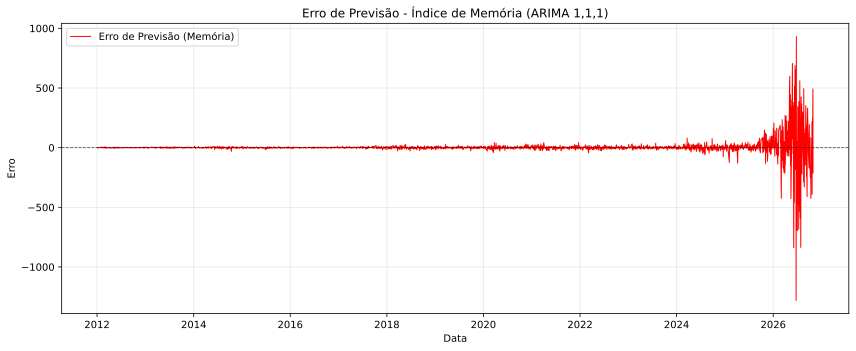

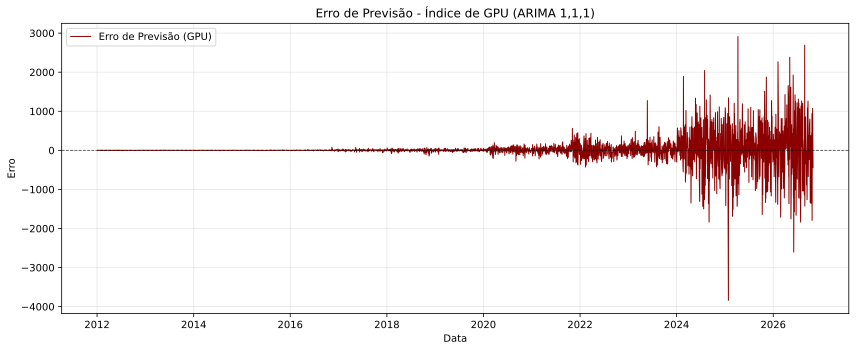

In [ ]:
import matplotlib.pyplot as plt

# --- 1. Gráfico de Erro de Previsão para o Índice de Memória (ARIMA 1,1,1) ---
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(comparacao_mem_df.index, comparacao_mem_df['Erro'], label='Erro de Previsão (Memória)', color='red', lw=1)
ax.axhline(y=0, linestyle='--', color='black', linewidth=0.8, alpha=0.7)
ax.set_title('Erro de Previsão - Índice de Memória (ARIMA 1,1,1)')
ax.set_xlabel('Data')
ax.set_ylabel('Erro')
ax.legend()
plt.tight_layout()
plt.show()

# --- 2. Gráfico de Erro de Previsão para o Índice de GPU (ARIMA 1,1,1) ---
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(comparacao_gpu_df.index, comparacao_gpu_df['Erro'], label='Erro de Previsão (GPU)', color='darkred', lw=1)
ax.axhline(y=0, linestyle='--', color='black', linewidth=0.8, alpha=0.7)
ax.set_title('Erro de Previsão - Índice de GPU (ARIMA 1,1,1)')
ax.set_xlabel('Data')
ax.set_ylabel('Erro')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

# --- 1. Teste ADF para os erros do Índice de Memória (ARIMA 1,1,1) ---
print('==================================================')
print('   TESTE ADF NOS ERROS - ÍNDICE DE MEMÓRIA')
print('==================================================')
res_adf_erro_mem = adfuller(comparacao_mem_df['Erro'].dropna())
print('Estatística do Teste: {:.4f}'.format(res_adf_erro_mem[0]))
print('Valor-p: {:.10f}'.format(res_adf_erro_mem[1]))
print('Valores Críticos:')
for key, value in res_adf_erro_mem[4].items():
    print('	{}: {:.4f}'.format(key, value))
print('Conclusão: Erros são {}'.format('ESTACIONÁRIOS' if res_adf_erro_mem[1] < 0.05 else 'NÃO ESTACIONÁRIOS'))
print('==================================================\n')

# --- 2. Teste ADF para os erros do Índice de GPU (ARIMA 1,1,1) ---
print('==================================================')
print('     TESTE ADF NOS ERROS - ÍNDICE DE GPU')
print('==================================================')
res_adf_erro_gpu = adfuller(comparacao_gpu_df['Erro'].dropna())
print('Estatística do Teste: {:.4f}'.format(res_adf_erro_gpu[0]))
print('Valor-p: {:.10f}'.format(res_adf_erro_gpu[1]))
print('Valores Críticos:')
for key, value in res_adf_erro_gpu[4].items():
    print('	{}: {:.4f}'.format(key, value))
print('Conclusão: Erros são {}'.format('ESTACIONÁRIOS' if res_adf_erro_gpu[1] < 0.05 else 'NÃO ESTACIONÁRIOS'))
print('==================================================')

   TESTE ADF NOS ERROS - ÍNDICE DE MEMÓRIA


/tmp/ipykernel_1038/2777356219.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_adf_erro_mem = adfuller(comparacao_mem_df['Erro'].dropna())


Estatística do Teste: -11.8136
Valor-p: 0.0000000000
Valores Críticos:
	1%: -3.4323
	5%: -2.8624
	10%: -2.5672
Conclusão: Erros são ESTACIONÁRIOS

     TESTE ADF NOS ERROS - ÍNDICE DE GPU
Estatística do Teste: -10.3058
Valor-p: 0.0000000000
Valores Críticos:
	1%: -3.4321
	5%: -2.8623
	10%: -2.5672
Conclusão: Erros são ESTACIONÁRIOS


/tmp/ipykernel_1038/2777356219.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_adf_erro_gpu = adfuller(comparacao_gpu_df['Erro'].dropna())


In [ ]:
from sklearn.metrics import mean_squared_error
import pandas as pd

# --- 1. Preparar previsões do modelo ARIMA(2,1,2) ---
in_sample_pred_mem_212 = result_mem_212.fittedvalues[1:]
observado_mem_212 = painel_100['INDICE_MEMORIA'][1:]
comparacao_mem_212_df = pd.DataFrame({
    'Observado': observado_mem_212,
    'Previsto': in_sample_pred_mem_212
})

in_sample_pred_gpu_212 = result_gpu_212.fittedvalues[1:]
observado_gpu_212 = painel_gpu_100['INDICE_GPU'][1:]
comparacao_gpu_212_df = pd.DataFrame({
    'Observado': observado_gpu_212,
    'Previsto': in_sample_pred_gpu_212
})

# --- 2. Calcular MSE para o Índice de Memória ---
mse_mem_111 = mean_squared_error(comparacao_mem_df['Observado'], comparacao_mem_df['Previsto'])
mse_mem_212 = mean_squared_error(comparacao_mem_212_df['Observado'], comparacao_mem_212_df['Previsto'])

# --- 3. Calcular MSE para o Índice de GPU ---
mse_gpu_111 = mean_squared_error(comparacao_gpu_df['Observado'], comparacao_gpu_df['Previsto'])
mse_gpu_212 = mean_squared_error(comparacao_gpu_212_df['Observado'], comparacao_gpu_212_df['Previsto'])

# --- 4. Exibir resultados ---
print('==================================================')
print('      ERRO QUADRÁTICO MÉDIO (MSE) - MEMÓRIA')
print('==================================================')
print(f'Modelo ARIMA(1,1,1): {mse_mem_111:.4f}')
print(f'Modelo ARIMA(2,1,2): {mse_mem_212:.4f}')
print('==================================================\n')

print('==================================================')
print('        ERRO QUADRÁTICO MÉDIO (MSE) - GPU')
print('==================================================')
print(f'Modelo ARIMA(1,1,1): {mse_gpu_111:.4f}')
print(f'Modelo ARIMA(2,1,2): {mse_gpu_212:.4f}')
print('==================================================')

      ERRO QUADRÁTICO MÉDIO (MSE) - MEMÓRIA
Modelo ARIMA(1,1,1): 5001.1406
Modelo ARIMA(2,1,2): 4595.7071

        ERRO QUADRÁTICO MÉDIO (MSE) - GPU
Modelo ARIMA(1,1,1): 97086.7346
Modelo ARIMA(2,1,2): 96521.4785


In [ ]:
# Exportando os dados do Índice de GPU (diário) para um arquivo CSV
painel_gpu_100.to_csv('indice_gpu_diario.csv', sep=';', decimal=',')

print('Arquivo gerado:')
print('  indice_gpu_diario.csv — índice base 100 diário das GPUs (NVDA e AMD)')

Arquivo gerado:
  indice_gpu_diario.csv — índice base 100 diário das GPUs (NVDA e AMD)
